# Tugas 3 — Temuan pada Korpus (Bagian B)

Visualisasi Data Lanjut (CAK7AGB4) · NIM 203012420009

Membaca `../datasets/aduan_bersih.csv` (hasil `00_audit_pembersihan.ipynb`). Gambar disimpan ke `figure/`.

Alur: pokok keluhan dari NMF atas TF-IDF → cek kata yang dipakai lebih dari satu pokok → beri label → ukuran tiap pokok → perkembangan per bulan.

Sel bertanda **TODO** berisi keputusan dan keterangan gambar yang ditulis sendiri.

In [1]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

FIG = Path("figure")
FIG.mkdir(exist_ok=True)

BIRU, ORANYE, ABU = "#2a78d6", "#eb6834", "#c4c2bb"
TEKS, TEKS2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 110, "savefig.dpi": 200,
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.edgecolor": TEKS2, "axes.labelcolor": TEKS, "xtick.color": TEKS2, "ytick.color": TEKS2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
})

PAKAI_STEM = False  # samakan dengan keputusan di notebook 00
df = pd.read_csv("../datasets/aduan_bersih.csv", parse_dates=["tanggal"])
df["token"] = df["token"].fillna("")
df["token_stem"] = df["token_stem"].fillna("")
KOLOM = "token_stem" if PAKAI_STEM else "token"
df["bulan"] = df["tanggal"].dt.to_period("M")
BULAN = pd.period_range(df["bulan"].min(), df["bulan"].max(), freq="M")
print(len(df), "aduan unik |", df["n_kirim"].sum(), "kiriman |", BULAN[0], "s.d.", BULAN[-1])

/home/bdo/.local/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:14: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.0)
  from scipy.sparse import csr_matrix, issparse


4785 aduan unik | 4935 kiriman | 2025-09 s.d. 2026-08


## 1. Pokok keluhan (NMF)

In [2]:
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.5, token_pattern=r"\S+")
X = vec.fit_transform(df[KOLOM])
istilah = np.array(vec.get_feature_names_out())
print("dokumen × istilah:", X.shape)

# bantu pilih K: galat rekonstruksi per K (cari siku)
galat = {k: NMF(k, init="nndsvd", random_state=0, max_iter=500).fit(X).reconstruction_err_
         for k in range(4, 16)}
pd.Series(galat, name="galat").round(2)

dokumen × istilah: (4785, 756)


4     64.51
5     63.57
6     62.63
7     61.72
8     60.76
9     59.88
10    59.10
11    58.26
12    57.34
13    56.71
14    56.07
15    55.03
Name: galat, dtype: float64

In [3]:
# pembanding beberapa K: 5 istilah teratas per topik + jumlah dokumen dominan
def ringkas_k(k):
    m = NMF(k, init="nndsvd", random_state=0, max_iter=500)
    w = m.fit_transform(X)
    n = np.bincount(w.argmax(axis=1), minlength=k)
    return pd.DataFrame({"n_dok": n, "istilah": [" | ".join(istilah[h.argsort()[::-1][:5]]) for h in m.components_]})

for k in [8, 12, 16, 20]:
    print(f"\nK = {k}")
    print(ringkas_k(k).sort_values("n_dok", ascending=False).to_string())


K = 8
   n_dok                                                                              istilah
4    958                             air | menggenang | air menggenang | mengalir | air tidak
1    943                                      lampu | lampu jalan | mati | jalan mati | total
5    576              badan jalan | badan | sampah berserakan | berserakan | berserakan badan
0    573  jalan berlubang | berlubang | perjalanan warga | mengganggu perjalanan | mengganggu
2    543                     petugas | datang | petugas sampah | tidak datang | datang selama
6    529                              sampah jalan | sampah | menyengat | bau | bau menyengat
3    456                                  jalan rusak | rusak | bulan tidak | berbatu | bulan
7    207                      lubang | lubang besar | membuat | membuat pengendara | terjatuh

K = 12


    n_dok                                                                              istilah
1     765                                      lampu jalan | mati | jalan mati | lampu | total
4     764                             air | menggenang | air menggenang | mengalir | air tidak
5     572              badan | badan jalan | berserakan | sampah berserakan | berserakan badan
3     415                              jalan rusak | rusak | bulan tidak | bulan | sejak bulan
2     406              petugas | selama minggu | sampah tidak | datang selama | petugas sampah
0     400  jalan berlubang | berlubang | perjalanan warga | mengganggu perjalanan | perjalanan
11    302                                          pju | lampu pju | padam | padam lama | lama
8     288                       bak sampah | meluber | meluber trotoar | penuh meluber | penuh
9     258                           menyala | sekali | jalan umum | sama sekali | menyala sama
6     244                      bau | menyengat | b

    n_dok                                                                              istilah
1     740                                      lampu jalan | mati | jalan mati | lampu | total
4     536                             air | air menggenang | menggenang | mengalir | air tidak
5     512              badan jalan | badan | berserakan | sampah berserakan | berserakan badan
13    495                         warga | tidak digubris | beberapa kali | beberapa | digubris
3     386                            jalan rusak | rusak | berbatu | bulan tidak | sejak bulan
0     338  jalan berlubang | berlubang | perjalanan warga | mengganggu perjalanan | perjalanan
6     236                         bau | menyengat | tumpukan sampah | tumpukan | bau menyengat
9     222                                   menyala | sekali | jalan umum | sama sekali | sama
7     202             membuat pengendara | lubang | lubang besar | terjatuh | pengendara motor
2     202                 tidak datang | datang se

    n_dok                                                                              istilah
4     492                             air | menggenang | air menggenang | mengalir | air tidak
13    372                         warga | tidak digubris | beberapa kali | beberapa | digubris
3     367                                  jalan rusak | rusak | bulan | bulan tidak | berbatu
16    328                                mati | jalan mati | lampu jalan | copet malam | copet
0     310  jalan berlubang | berlubang | perjalanan warga | mengganggu perjalanan | perjalanan
19    265              sampah berserakan | berserakan | berserakan badan | badan jalan | badan
17    256                          tiang lampu | menyala redup | redup | tiang | jalan menyala
6     233                      bau | menyengat | bau menyengat | menimbulkan bau | menimbulkan
18    231          dibiarkan | khawatir terjadi | khawatir | kecelakaan dibiarkan | kecelakaan
5     224                      parkir | badan jala

### Istilah yang paling naik

Tidak bergantung pada K: jumlah aduan yang memuat tiap istilah, rata-rata per bulan pada periode awal vs akhir.
Membantu menemukan pokok bervolume kecil yang sedang naik, yang bisa tenggelam di dalam topik besar.

In [4]:
N_AWAL, N_AKHIR = 6, 3  # panjang periode pembanding (bulan)
ada = pd.DataFrame((X > 0).toarray(), columns=istilah)
per_bulan = ada.groupby(df["bulan"].values).sum().reindex(BULAN, fill_value=0)
naik = pd.DataFrame({"total": per_bulan.sum(),
                     "rata_awal": per_bulan.iloc[:N_AWAL].mean(),
                     "rata_akhir": per_bulan.iloc[-N_AKHIR:].mean()})
naik["rasio"] = naik["rata_akhir"] / naik["rata_awal"].clip(lower=0.5)
naik[naik["total"] >= 20].sort_values("rasio", ascending=False).head(25).round(2)

,total,rata_awal,rata_akhir,rasio
keruh kekuningan,27,0.67,6.00,9.00
kekuningan,27,0.67,6.00,9.00
air bersih,30,1.00,6.33,6.33
bersih keruh,30,1.00,6.33,6.33
lumpur,30,1.00,6.33,6.33
mandi,30,1.00,6.33,6.33
lumpur bak,30,1.00,6.33,6.33
mengendap,30,1.00,6.33,6.33
mengendap lumpur,30,1.00,6.33,6.33
bak mandi,30,1.00,6.33,6.33


In [5]:
K = 16  # kurva galat tanpa siku jelas; dipilih dari keterbacaan topik (pembanding K di atas)
nmf = NMF(K, init="nndsvd", random_state=0, max_iter=500)
W = nmf.fit_transform(X)
H = nmf.components_

N_ATAS = 12
atas = pd.DataFrame({f"T{k}": istilah[H[k].argsort()[::-1][:N_ATAS]] for k in range(K)})
atas

,T0,T1,T2,T3,T4,T5,T6,T7,T8,T9,T10,T11,T12,T13,T14,T15
0,jalan berlubang,lampu jalan,tidak datang,jalan rusak,air,badan jalan,bau,membuat pengendara,penuh meluber,menyala,mengelupas sepanjang,pju,diangkut petugas,warga,seluruh,banjir
1,berlubang,mati,datang selama,rusak,air menggenang,badan,menyengat,lubang,meluber,sekali,mengelupas,padam,tidak diangkut,tidak digubris,pedagang,lutut hujan
2,perjalanan warga,jalan mati,sampah tidak,berbatu,menggenang,berserakan,tumpukan sampah,lubang besar,meluber trotoar,jalan umum,jalan mengelupas,lampu pju,diangkut,beberapa kali,lima,deras
3,mengganggu perjalanan,lampu,selama,bulan tidak,mengalir,sampah berserakan,tumpukan,terjatuh,penuh,sama sekali,aspal jalan,padam lama,sampah menumpuk,beberapa,lima memakai,hujan deras
4,perjalanan,total,selama minggu,sejak bulan,air tidak,berserakan badan,bau menyengat,pengendara motor,bak sampah,sama,aspal,lama,tps,digubris,memakai,lutut
5,mengganggu,jalanan gelap,petugas sampah,bulan,tidak mengalir,parkir,menimbulkan bau,membuat,bak,penerangan jalan,sepanjang,pju padam,menumpuk,warga beberapa,kaki lima,banjir setinggi
6,berlubang jalan,jalanan,datang,rusak berbatu,gorong,separuh,menimbulkan,motor terjatuh,trotoar,penerangan,sepanjang jalan,lampu,menumpuk tps,kali,memakai seluruh,setinggi
7,warga,gelap,minggu,sejak,mengalir air,separuh badan,jalan menimbulkan,pengendara,sampah penuh,tidak menyala,bertugas aspal,lama mengganggu,petugas,kali menegur,kaki,setinggi lutut
8,berbahaya,gelap total,petugas,rusak parah,saluran air,liar,sampah jalan,besar,sampah,menyala sama,warga aspal,lama kiranya,sampah,menegur tidak,pedagang kaki,hujan
9,sangat berbahaya,total lampu,sampah,parah,saluran,menutup,sampah,motor,jalan penuh,umum,mengganggu aspal,rakyat padam,tps tidak,menegur,seluruh trotoar,deras jalan


## 2. Satu kata, lebih dari satu pokok?

Istilah yang masuk daftar teratas di ≥2 topik, beserta pasangan kata (bigram) yang paling sering menyertainya.
Bahan untuk memutuskan apakah satu topik perlu dipecah atau dua topik disatukan.

In [6]:
muncul = Counter(w for k in range(K) for w in atas[f"T{k}"])
kata_bersama = [w for w, n in muncul.items() if n >= 2 and " " not in w]
print("istilah di ≥2 topik:", kata_bersama)

bigram = Counter(b for ws in df[KOLOM].str.split() for b in zip(ws, ws[1:]))
for w in kata_bersama:
    pasangan = [(" ".join(b), n) for b, n in bigram.most_common() if w in b][:10]
    topik = [f"T{k}" for k in range(K) if w in set(atas[f"T{k}"])]
    print(f"\n{w} ({', '.join(topik)}):", pasangan)

istilah di ≥2 topik: ['warga', 'lampu', 'petugas', 'sampah', 'tidak', 'trotoar']

warga (T0, T13): [('mengganggu warga', 604), ('warga beberapa', 229), ('perjalanan warga', 180), ('warga membuang', 106), ('warga jalan', 62), ('jalan warga', 54), ('warga sampah', 40), ('warga air', 38), ('warga lampu', 33), ('warga petugas', 26)]

lampu (T1, T11): [('lampu jalan', 629), ('lampu pju', 158), ('total lampu', 157), ('tiang lampu', 129), ('menutupi lampu', 79), ('bertugas lampu', 44), ('warga lampu', 33), ('mengganggu lampu', 15)]

petugas (T2, T12): [('petugas bertugas', 460), ('petugas datang', 275), ('petugas sampah', 178), ('diangkut petugas', 156), ('jalan petugas', 57), ('warga petugas', 26), ('bertugas petugas', 15), ('malam petugas', 13), ('berbahaya petugas', 13), ('petugas warga', 12)]

sampah (T2, T6, T8, T12): [('sampah jalan', 227), ('petugas sampah', 178), ('sampah tidak', 178), ('bak sampah', 172), ('tumpukan sampah', 158), ('sampah menumpuk', 156), ('sampah berserakan', 147),

In [7]:
# TODO kata yang ingin diperiksa sendiri: sebaran topik dominan dokumen yang memuatnya
CEK = kata_bersama[:3]
dom = W.argmax(axis=1)
pd.DataFrame({w: pd.Series(dom[df[KOLOM].str.split().map(lambda ws: w in ws).values]).value_counts()
              for w in CEK}).fillna(0).astype(int).rename(index=lambda k: f"T{k}")

,warga,lampu,petugas
T0,215,0,61
T1,166,600,115
T2,52,0,202
T3,88,0,49
T4,128,0,81
T5,102,0,78
T6,54,0,40
T7,39,0,26
T8,32,0,19
T9,45,1,22


## 3. Pokok keluhan: pecah & gabung

Kriteria: topik digabung bila jenis kerusakannya sama; dipisah bila kerusakannya berbeda walau objek/katanya sama.

1. Topik dominan NMF per aduan (bobot < `AMBANG` → "Tidak jelas").
2. Topik "air" dipecah dengan aturan kata: keruh → genangan → tidak mengalir.
3. Topik "badan jalan" dipecah: parkir liar vs sampah berserakan.
4. Topik NMF yang kerusakannya sama digabung (`GABUNG`).
5. Aduan "Tidak jelas" yang berisi tema kecil konsisten dikelompokkan dengan aturan kata (pohon, kabel, bising bengkel, angkutan).
6. Seluruh aduan berpenanda keruh → "Air keruh" (aturan berlaku untuk semua aduan, bukan hanya topik air).
7. Topik T13 ("warga, tidak digubris, menegur, limbah, jebol") dipecah: limbah ke saluran → sampah, drainase jebol → genangan, "beberapa kali menegur, tidak digubris" → respon lambat.

In [8]:
AMBANG = 0.02
dom = W.argmax(axis=1)
bobot = W.max(axis=1)
T_AIR = [k for k in range(K) if atas[f"T{k}"][0] == "air"]
T_BADAN = [k for k in range(K) if atas[f"T{k}"][0] == "badan jalan"]
print("topik air:", T_AIR, "| topik badan jalan:", T_BADAN)

KERUH = {"keruh", "kekuningan", "lumpur", "coklat", "kaporit", "mengendap"}
ATURAN = {
    "air": [("air keruh", KERUH),
            ("genangan", {"menggenang", "banjir", "saluran", "gorong", "drainase", "lutut", "meluber"}),
            ("air tidak mengalir", {"mengalir", "pdam", "keran"})],
    "badan": [("parkir liar", {"parkir", "liar"}),
              ("sampah", {"sampah", "berserakan"})],
}

def pecah(teks, aturan):
    ws = set(teks.split())
    for label, penanda in aturan:
        if ws & penanda:
            return label
    return "Tidak jelas"

# topik NMF dengan jenis kerusakan sama → satu kunci kelompok
GABUNG = {0: "jalan", 3: "jalan", 7: "jalan", 10: "jalan",
          1: "lampu", 9: "lampu", 11: "lampu",
          2: "sampah", 6: "sampah", 8: "sampah", 12: "sampah",
          15: "genangan", 13: "T13", 14: "pkl"}
for k in range(K):
    print(f"T{k:<2} → {GABUNG.get(k, 'dipecah aturan' if k in T_AIR + T_BADAN else '?'):15s}",
          " | ".join(atas[f"T{k}"][:4]))

topik air: [4] | topik badan jalan: [5]
T0  → jalan           jalan berlubang | berlubang | perjalanan warga | mengganggu perjalanan
T1  → lampu           lampu jalan | mati | jalan mati | lampu
T2  → sampah          tidak datang | datang selama | sampah tidak | selama
T3  → jalan           jalan rusak | rusak | berbatu | bulan tidak
T4  → dipecah aturan  air | air menggenang | menggenang | mengalir
T5  → dipecah aturan  badan jalan | badan | berserakan | sampah berserakan
T6  → sampah          bau | menyengat | tumpukan sampah | tumpukan
T7  → jalan           membuat pengendara | lubang | lubang besar | terjatuh
T8  → sampah          penuh meluber | meluber | meluber trotoar | penuh
T9  → lampu           menyala | sekali | jalan umum | sama sekali
T10 → jalan           mengelupas sepanjang | mengelupas | jalan mengelupas | aspal jalan
T11 → lampu           pju | padam | lampu pju | padam lama
T12 → sampah          diangkut petugas | tidak diangkut | diangkut | sampah menumpuk
T13 → T1

In [9]:
kelompok = []
for i, k in enumerate(dom):
    teks = df[KOLOM].iat[i]
    if bobot[i] < AMBANG:
        kelompok.append("Tidak jelas")
    elif k in T_AIR:
        kelompok.append(pecah(teks, ATURAN["air"]))
    elif k in T_BADAN:
        kelompok.append(pecah(teks, ATURAN["badan"]))
    else:
        kelompok.append(GABUNG.get(k, f"T{k}"))
df["kelompok"] = kelompok

# aduan "Tidak jelas" berisi tema kecil yang konsisten → aturan kata (kriteria yang sama)
ATURAN["sisa"] = [("pohon", {"lapuk", "miring", "tumbang"}),
                  ("kabel menjuntai", {"kabel", "menjuntai"}),
                  ("bising bengkel", {"bising", "bengkel"}),
                  ("angkutan berhenti sembarangan", {"angkutan", "berhenti", "sembarangan"})]
tj = df["kelompok"] == "Tidak jelas"
df.loc[tj, "kelompok"] = df.loc[tj, KOLOM].map(lambda t: pecah(t, ATURAN["sisa"]))
print("dari Tidak jelas:", df.loc[tj, "kelompok"].value_counts().to_string(), sep="\n")

keruh =df[KOLOM].str.split().map(lambda ws: bool(set(ws) & KERUH))
pindah = keruh & (df["kelompok"] != "air keruh")
print("aduan berpenanda keruh dipindah dari kelompok lain:", pindah.sum())
print(df.loc[pindah, "kelompok"].value_counts().to_string())
df.loc[keruh, "kelompok"] = "air keruh"
print()
print(df["kelompok"].value_counts().to_string())
# rincian hasil pecah per topik NMF asal (untuk laporan B1)
asal = pd.Series([f"T{k}" for k in dom], index=df.index)
rinci = pd.crosstab(df["kelompok"], asal).loc[:, [f"T{k}" for k in T_AIR + T_BADAN]]
print(rinci[rinci.sum(axis=1) > 0].to_string())

dari Tidak jelas:
kelompok
pohon                            126
angkutan berhenti sembarangan     67
kabel menjuntai                   64
bising bengkel                    51
Tidak jelas                        2
aduan berpenanda keruh dipindah dari kelompok lain: 25
kelompok
sampah    20
T13        5

kelompok
lampu                            1089
jalan                            1072
sampah                            888
genangan                          433
T13                               426
parkir liar                       223
air keruh                         146
pohon                             126
pkl                               108
air tidak mengalir                 90
angkutan berhenti sembarangan      67
kabel menjuntai                    64
bising bengkel                     51
Tidak jelas                         2
col_0                           T4   T5
kelompok                               
Tidak jelas                      2    0
air keruh                      121  

In [10]:
# profil T13: kata, pasangan kata, dan tiga kata berurutan terbanyak
ws13 = df.loc[df["kelompok"] == "T13", KOLOM].str.split()
print(len(ws13), "aduan")
print(Counter(w for x in ws13 for w in x).most_common(20))
print(Counter(" ".join(b) for x in ws13 for b in zip(x, x[1:])).most_common(15))
print(Counter(" ".join(b) for x in ws13 for b in zip(x, x[1:], x[2:])).most_common(15))
print(df.loc[df["kelompok"] == "T13", "kategori_dilaporkan"].value_counts().to_string())
# kemunculan bersama tiga pola utama
pola13 = pd.DataFrame({"menegur": ws13.map(lambda x: "menegur" in x),
                       "limbah": ws13.map(lambda x: "limbah" in x),
                       "jebol": ws13.map(lambda x: "jebol" in x)})
print(pola13.value_counts().to_string())

426 aduan
[('warga', 462), ('tidak', 239), ('beberapa', 203), ('kali', 203), ('menegur', 203), ('digubris', 203), ('jalan', 167), ('mengganggu', 150), ('saluran', 113), ('limbah', 108), ('membuang', 106), ('drainase', 102), ('jebol', 102), ('perlu', 102), ('petugas', 63), ('tiang', 42), ('anak', 39), ('listrik', 39), ('melewati', 35), ('waktu', 34)]
[('warga beberapa', 203), ('beberapa kali', 203), ('kali menegur', 203), ('menegur tidak', 203), ('tidak digubris', 203), ('warga membuang', 106), ('membuang limbah', 106), ('limbah saluran', 106), ('jebol perlu', 102), ('mengganggu warga', 96), ('drainase jebol', 78), ('tiang listrik', 37), ('digubris mengganggu', 35), ('anak melewati', 35), ('jalan warga', 35)]
[('warga beberapa kali', 203), ('beberapa kali menegur', 203), ('kali menegur tidak', 203), ('menegur tidak digubris', 203), ('warga membuang limbah', 106), ('membuang limbah saluran', 106), ('drainase jebol perlu', 78), ('tidak digubris mengganggu', 35), ('jalan warga beberapa', 3

In [11]:
# T13 dipecah: masalah yang disebut didahulukan (limbah → sampah, drainase jebol → genangan),
# lalu pola "menegur, tidak digubris" → respon lambat; sisanya lewat aturan tema kecil
ATURAN["T13"] = [("sampah", {"limbah"}),
                 ("genangan", {"jebol"}),
                 ("respon lambat", {"menegur", "digubris"})]
m13 = df["kelompok"] == "T13"
df.loc[m13, "kelompok"] = df.loc[m13, KOLOM].map(lambda t: pecah(t, ATURAN["T13"] + ATURAN["sisa"]))
print(df.loc[m13, "kelompok"].value_counts().to_string())
print()
print(df["kelompok"].value_counts().to_string())

kelompok
respon lambat                    176
sampah                           108
genangan                         102
pohon                             18
angkutan berhenti sembarangan     16
bising bengkel                     5
Tidak jelas                        1

kelompok
lampu                            1089
jalan                            1072
sampah                            996
genangan                          535
parkir liar                       223
respon lambat                     176
air keruh                         146
pohon                             144
pkl                               108
air tidak mengalir                 90
angkutan berhenti sembarangan      83
kabel menjuntai                    64
bising bengkel                     56
Tidak jelas                         3


In [12]:
# isi "Tidak jelas": kata & pasangan kata terbanyak, dipisah menurut asal topik NMF
tj = df["kelompok"] == "Tidak jelas"
for asal, m in [("bobot rendah", tj & (bobot < AMBANG)), ("air / badan jalan", tj & (bobot >= AMBANG))]:
    ws = df.loc[m, KOLOM].str.split()
    print(f"\n{asal}: {m.sum()} aduan")
    print(Counter(w for x in ws for w in x).most_common(15))
    print(Counter(" ".join(b) for x in ws for b in zip(x, x[1:])).most_common(10))


bobot rendah: 0 aduan
[]
[]

air / badan jalan: 3 aduan
[('warga', 4), ('aliran', 2), ('air', 2), ('kecil', 2), ('sekali', 2), ('jam', 2), ('sibuk', 2), ('petugas', 2), ('datang', 2), ('meninjau', 2), ('langsung', 2), ('mengganggu', 2), ('trotoar', 1), ('dipakai', 1), ('parkir', 1)]
[('aliran air', 2), ('air kecil', 2), ('kecil sekali', 2), ('sekali jam', 2), ('jam sibuk', 2), ('sibuk petugas', 2), ('petugas datang', 2), ('datang meninjau', 2), ('meninjau langsung', 2), ('mengganggu warga', 2)]


In [13]:
# TODO ganti label tampilan dengan kata-kata sendiri (dipakai di gambar)
LABEL_AKHIR = {k: k for k in df["kelompok"].unique()}
# LABEL_AKHIR["jalan"] = "..."
df["topik"] = df["kelompok"].map(LABEL_AKHIR)

# pemeriksaan silang dengan kategori pilihan warga
pd.crosstab(df["topik"], df["kategori_dilaporkan"], margins=True)

kategori_dilaporkan,Air Bersih,Drainase dan Banjir,Fasilitas Umum,Jalan Rusak,Ketertiban Umum,Lain-lain,Penerangan Jalan,Sampah,All
topik,,,,,,,,,
Tidak jelas,1,1,1,0,0,0,0,0,3
air keruh,111,5,6,3,5,4,7,5,146
air tidak mengalir,78,1,2,3,3,1,1,1,90
angkutan berhenti sembarangan,1,4,4,2,67,0,2,3,83
bising bengkel,0,0,1,2,2,47,3,1,56
genangan,16,409,17,18,22,16,25,12,535
jalan,45,31,120,729,45,42,36,24,1072
kabel menjuntai,3,0,48,4,1,3,3,2,64
lampu,140,42,113,33,31,66,637,27,1089


## Gambar 1 — Ukuran tiap pokok keluhan

In [14]:
ukuran = df["topik"].value_counts()
kirim = df.groupby("topik")["n_kirim"].sum().reindex(ukuran.index)
tabel_ukuran = pd.DataFrame({"aduan": ukuran, "persen": (ukuran / ukuran.sum() * 100).round(1),
                             "kiriman": kirim})
tabel_ukuran

,aduan,persen,kiriman
topik,,,
lampu,1089,22.8,1105
jalan,1072,22.4,1084
sampah,996,20.8,1006
genangan,535,11.2,539
parkir liar,223,4.7,226
respon lambat,176,3.7,176
air keruh,146,3.1,150
pohon,144,3.0,147
pkl,108,2.3,199


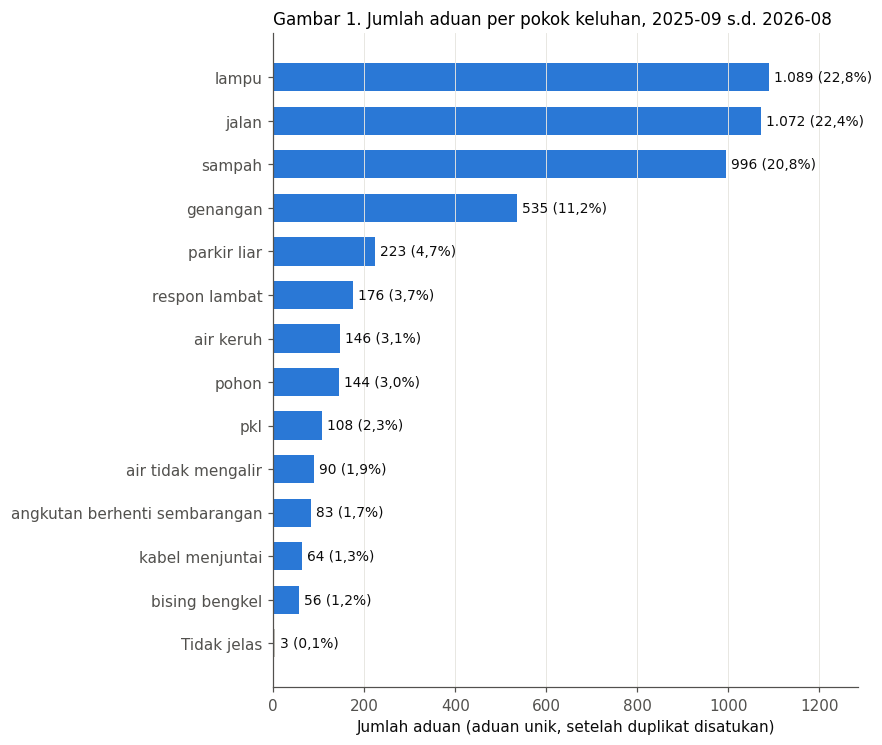

In [15]:
u = ukuran.sort_values()
fig, ax = plt.subplots(figsize=(8, 0.42 * len(u) + 1))
warna = [ABU if t == "Tidak jelas" else BIRU for t in u.index]
ax.barh(u.index, u.values, color=warna, height=0.65)
for i, v in enumerate(u.values):
    ax.text(v + u.max() * 0.01, i, f"{v:,}".replace(",", ".") + f" ({v / u.sum():.1%})".replace(".", ","),
            va="center", fontsize=9, color=TEKS)
ax.set_xlabel("Jumlah aduan (aduan unik, setelah duplikat disatukan)")
ax.set_title("Gambar 1. Jumlah aduan per pokok keluhan, " f"{BULAN[0]} s.d. {BULAN[-1]}", loc="left")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, u.max() * 1.18)
fig.tight_layout()
fig.savefig(FIG / "gambar1.png", bbox_inches="tight")

**Keterangan Gambar 1** — TODO tulis sendiri, sertakan angka.

## Gambar 2 — Pokok keluhan × bulan

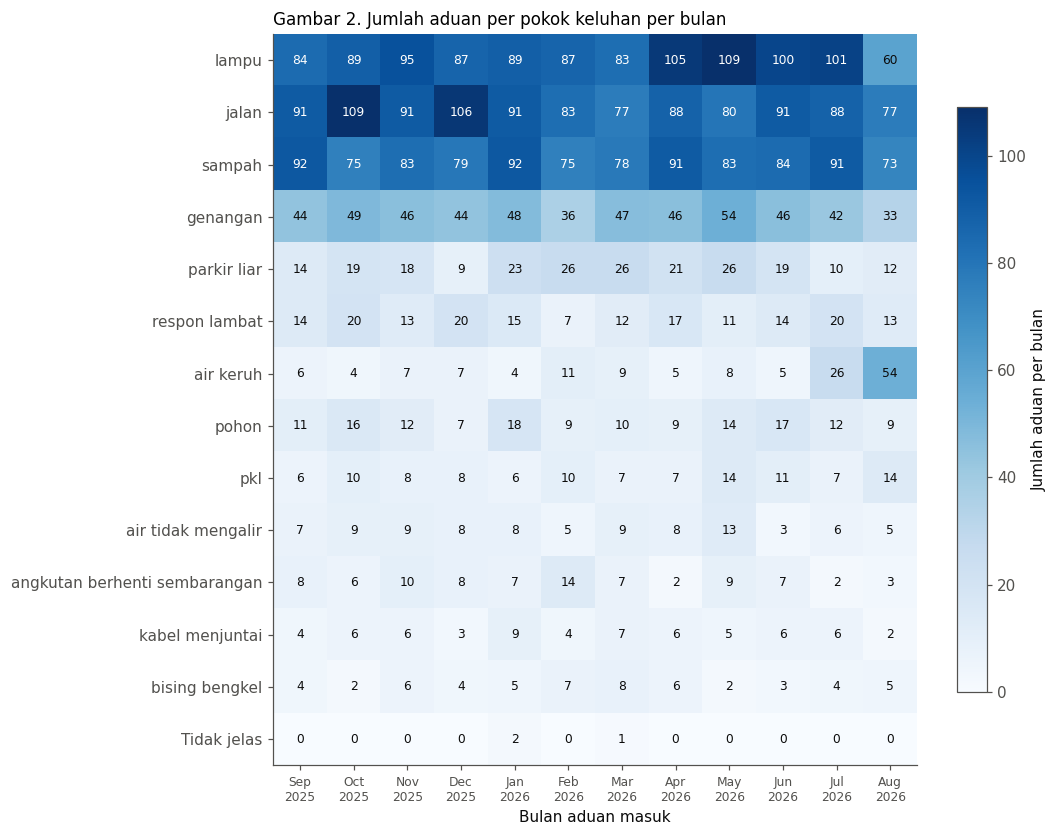

In [16]:
bulanan = (df.groupby(["topik", "bulan"]).size().unstack(fill_value=0)
             .reindex(columns=BULAN, fill_value=0).reindex(ukuran.index))
fig, ax = plt.subplots(figsize=(10, 0.45 * len(bulanan) + 1.4))
im = ax.imshow(bulanan.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(BULAN)), [b.strftime("%b\n%Y") for b in BULAN], fontsize=8)
ax.set_yticks(range(len(bulanan)), bulanan.index)
vmax = bulanan.values.max()
for i in range(bulanan.shape[0]):
    for j in range(bulanan.shape[1]):
        v = bulanan.values[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=8, color="white" if v > vmax * 0.6 else TEKS)
ax.grid(False)
ax.set_xlabel("Bulan aduan masuk")
fig.colorbar(im, ax=ax, label="Jumlah aduan per bulan", shrink=0.8)
ax.set_title("Gambar 2. Jumlah aduan per pokok keluhan per bulan", loc="left")
fig.tight_layout()
fig.savefig(FIG / "gambar2.png", bbox_inches="tight")

**Keterangan Gambar 2** — TODO.

## 3. Ukuran memburuk

Per pokok keluhan: rata-rata bulanan periode awal vs periode akhir, kemiringan tren (aduan/bulan),
dan bulan mulai naik = bulan pertama yang jumlahnya, dan semua bulan sesudahnya, berada di atas rata-rata awal + 2 simpangan baku (minimal 2 bulan berturut-turut).

In [17]:
x = np.arange(len(BULAN))

def mulai_naik(s, batas):
    # bulan pertama (setelah periode awal) yang nilainya, dan semua bulan sesudahnya, di atas batas;
    # minimal 2 bulan berturut-turut agar lonjakan satu bulan tidak terhitung
    di_atas = s > batas
    for j in range(N_AWAL, len(s) - 1):
        if di_atas.iloc[j:].all():
            return s.index[j]
    return None

baris = []
for t, s in bulanan.drop("Tidak jelas", errors="ignore").iterrows():
    awal, akhir = s.iloc[:N_AWAL], s.iloc[-N_AKHIR:]
    batas = awal.mean() + 2 * awal.std()
    baris.append({"topik": t, "total": s.sum(), "rata_awal": awal.mean(), "rata_akhir": akhir.mean(),
                  "rasio": akhir.mean() / max(awal.mean(), 0.5),
                  "kemiringan": np.polyfit(x, s.values, 1)[0], "mulai_naik": mulai_naik(s, batas)})
tren = pd.DataFrame(baris).set_index("topik").sort_values("rasio", ascending=False).round(2)
tren

,total,rata_awal,rata_akhir,rasio,kemiringan,mulai_naik
topik,,,,,,
air keruh,146,6.50,28.33,4.36,2.51,2026-07
pkl,108,8.00,10.67,1.33,0.39,NaT
respon lambat,176,14.83,15.67,1.06,-0.13,NaT
pohon,144,12.17,12.67,1.04,-0.05,NaT
sampah,996,82.67,82.67,1.00,-0.13,NaT
lampu,1089,88.50,87.00,0.98,0.12,NaT
genangan,535,44.50,40.33,0.91,-0.45,NaT
jalan,1072,95.17,85.33,0.90,-1.71,NaT
kabel menjuntai,64,5.33,4.67,0.88,-0.06,NaT


In [18]:
# seandainya pokok "air" tidak dipecah: rasio gabungan
AIR = ["air keruh", "air tidak mengalir", "genangan"]
gab = tren.loc[AIR, ["rata_awal", "rata_akhir"]].sum()
print(gab.round(2).to_dict(), "| rasio gabungan:", round(gab["rata_akhir"] / gab["rata_awal"], 2))

{'rata_awal': 58.67, 'rata_akhir': 73.33} | rasio gabungan: 1.25


## Gambar 3 — Perubahan rata-rata bulanan tiap pokok keluhan

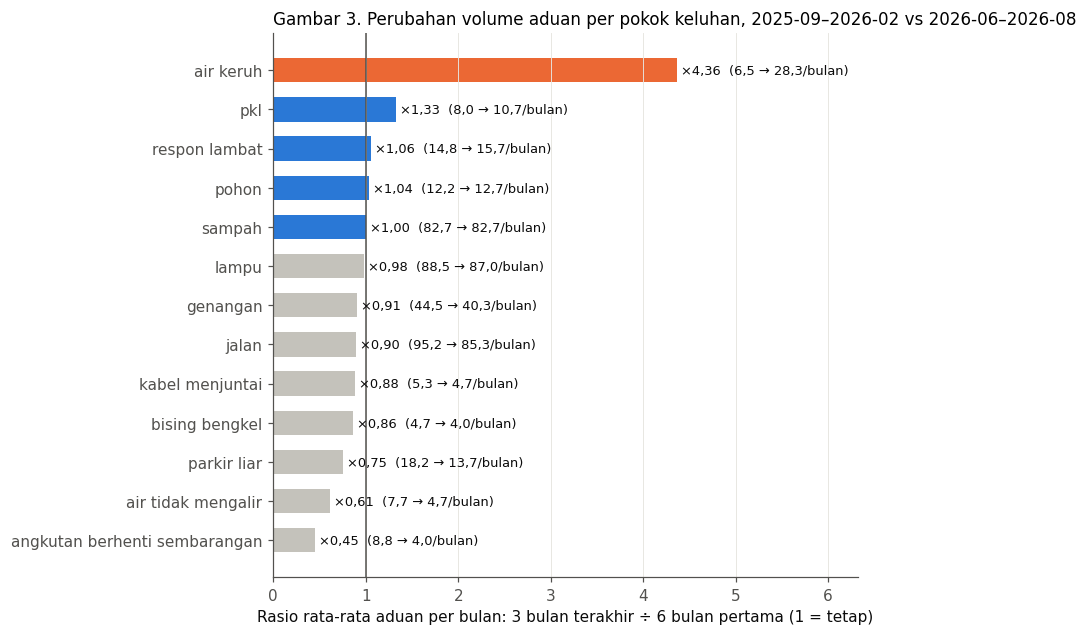

In [19]:
SOROT = list(tren.index[:1])  # pokok dengan rasio tertinggi
r = tren["rasio"].sort_values()
fig, ax = plt.subplots(figsize=(8, 0.36 * len(r) + 1.2))
warna = [ORANYE if t in SOROT else (BIRU if v >= 1 else ABU) for t, v in r.items()]
ax.barh(r.index, r.values, color=warna, height=0.62)
ax.axvline(1, color=TEKS2, lw=1)
for i, (t, v) in enumerate(r.items()):
    a, b = tren.loc[t, "rata_awal"], tren.loc[t, "rata_akhir"]
    ax.text(v + r.max() * 0.01, i, f"×{v:.2f}  ({a:.1f} → {b:.1f}/bulan)".replace(".", ","),
            va="center", fontsize=8.5, color=TEKS)
ax.set_xlim(0, r.max() * 1.45)
ax.set_xlabel(f"Rasio rata-rata aduan per bulan: {N_AKHIR} bulan terakhir ÷ {N_AWAL} bulan pertama (1 = tetap)")
ax.grid(axis="y", visible=False)
ax.set_title(f"Gambar 3. Perubahan volume aduan per pokok keluhan, "
             f"{BULAN[0]}–{BULAN[N_AWAL - 1]} vs {BULAN[-N_AKHIR]}–{BULAN[-1]}", loc="left")
fig.tight_layout()
fig.savefig(FIG / "gambar3.png", bbox_inches="tight")

**Keterangan Gambar 3** — TODO.

## Gambar 4 — Pokok keluhan yang disorot: jumlah dan porsi

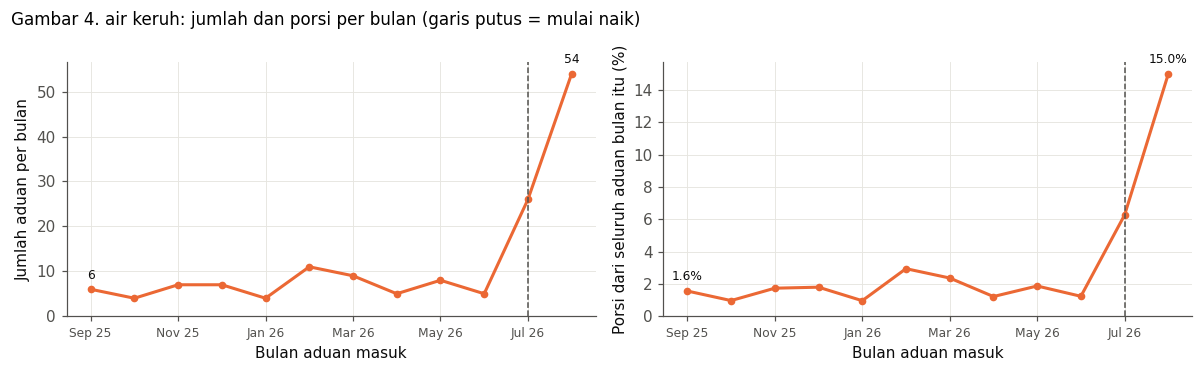

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for t in SOROT:
    s = bulanan.loc[t]
    porsi = s / bulanan.sum() * 100
    axes[0].plot(x, s.values, color=ORANYE, lw=2, marker="o", ms=4)
    axes[1].plot(x, porsi.values, color=ORANYE, lw=2, marker="o", ms=4)
    for ax, v, f in [(axes[0], s, "{:.0f}"), (axes[1], porsi, "{:.1f}%")]:
        for j in [0, len(x) - 1]:
            ax.annotate(f.format(v.iloc[j]), (x[j], v.iloc[j]), xytext=(0, 7),
                        textcoords="offset points", ha="center", fontsize=8, color=TEKS)
    m = tren.loc[t, "mulai_naik"]
    if pd.notna(m):
        for ax in axes:
            ax.axvline(list(BULAN).index(m), color=TEKS2, lw=1, ls="--")
axes[0].set_ylabel("Jumlah aduan per bulan")
axes[1].set_ylabel("Porsi dari seluruh aduan bulan itu (%)")
for ax in axes:
    ax.set_xticks(x[::2], [BULAN[i].strftime("%b %y") for i in x[::2]], fontsize=8)
    ax.set_xlabel("Bulan aduan masuk")
    ax.set_ylim(bottom=0)
fig.suptitle(f"Gambar 4. {', '.join(SOROT)}: jumlah dan porsi per bulan (garis putus = mulai naik)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "gambar4.png", bbox_inches="tight")

**Keterangan Gambar 4** — TODO.